In [ ]:

from google.colab import drive

drive.mount("/content/drive")

print("Google Drive connected successfully!")


In [5]:

from pathlib import Path

data_folder = Path(
    "/content/drive/MyDrive/QueueWise_Historical_Data"
)

files_found = (
    list(data_folder.glob("*.zip")) +
    list(data_folder.glob("*.csv"))
)

print("Total historical files:", len(files_found))
print("ZIP files:", len(list(data_folder.glob("*.zip"))))
print("CSV files:", len(list(data_folder.glob("*.csv"))))


Total historical files: 20
ZIP files: 20
CSV files: 0


In [6]:

import pandas as pd
import zipfile
import re
from pathlib import Path

data_folder = Path(
    "/content/drive/MyDrive/QueueWise_Historical_Data"
)

zip_files = sorted(data_folder.glob("*.zip"))
results = []

for file in zip_files:

    # Identify the month from the ZIP filename
    match = re.search(
        r"DM01-([A-Za-z]+)-(\d{4})",
        file.name,
        flags=re.IGNORECASE
    )

    if not match:
        results.append({
            "ZIP": file.name,
            "Month": "Unknown",
            "CSV Period": "Unknown",
            "Status": "CHECK FILENAME"
        })
        continue

    expected_period = (
        f"DM01-{match.group(1).upper()}-{match.group(2)}"
    )

    try:
        with zipfile.ZipFile(file) as z:

            # Find CSV files for this specific month
            csv_names = [
                name for name in z.namelist()
                if name.lower().endswith(".csv")
                and expected_period in Path(name).name.upper()
            ]

            if len(csv_names) != 1:
                actual_period = "Not uniquely found"
                status = "CHECK ZIP"
            else:
                with z.open(csv_names[0]) as csv:
                    sample = pd.read_csv(csv, nrows=2)

                actual_period = str(
                    sample["Period"].iloc[0]
                ).strip().upper()

                status = (
                    "OK" if actual_period == expected_period
                    else "PERIOD MISMATCH"
                )

    except Exception as e:
        actual_period = str(e)[:80]
        status = "ERROR"

    results.append({
        "ZIP": file.name,
        "Month": expected_period,
        "CSV Period": actual_period,
        "Status": status
    })

check_df = pd.DataFrame(results)

display(check_df)

expected_months = {
    f"DM01-{d.strftime('%B-%Y').upper()}"
    for d in pd.date_range(
        "2024-09-01", "2026-04-01", freq="MS"
    )
}

verified_months = set(
    check_df.loc[
        check_df["Status"] == "OK", "CSV Period"
    ]
)

print("Total ZIP files:", len(zip_files))
print("Successfully verified months:", len(verified_months))
print("Missing or unverified months:",
      sorted(expected_months - verified_months))
print("All checks passed:",
      len(verified_months) == 20
      and (check_df["Status"] == "OK").all())


,ZIP,Month,CSV Period,Status
0,DM01-APRIL-2025-full-extract_M0N7G.zip,DM01-APRIL-2025,DM01-APRIL-2025,OK
1,DM01-APRIL-2026-full-extract.zip,DM01-APRIL-2026,DM01-APRIL-2026,OK
2,DM01-AUGUST-2025-full-extract_M0N7G.zip,DM01-AUGUST-2025,DM01-AUGUST-2025,OK
3,DM01-DECEMBER-2024-full-extract.zip,DM01-DECEMBER-2024,DM01-DECEMBER-2024,OK
4,DM01-DECEMBER-2025-full-extract_5WSGC.zip,DM01-DECEMBER-2025,DM01-DECEMBER-2025,OK
5,DM01-FEBRUARY-2025-full-extract_M0N7G.zip,DM01-FEBRUARY-2025,DM01-FEBRUARY-2025,OK
6,DM01-FEBRUARY-2026-full-extract_5WSGC.zip,DM01-FEBRUARY-2026,DM01-FEBRUARY-2026,OK
7,DM01-JANUARY-2025-full-extract_M0N7G.zip,DM01-JANUARY-2025,DM01-JANUARY-2025,OK
8,DM01-JANUARY-2026-full-extract_5WSGC.zip,DM01-JANUARY-2026,DM01-JANUARY-2026,OK
9,DM01-JULY-2025-full-extract_M0N7G.zip,DM01-JULY-2025,DM01-JULY-2025,OK


Total ZIP files: 20
Successfully verified months: 20
Missing or unverified months: []
All checks passed: True


In [7]:

import pandas as pd
import zipfile
import re
from pathlib import Path

data_folder = Path(
    "/content/drive/MyDrive/QueueWise_Historical_Data"
)

# Columns used by Member 1
week_columns = [
    "00 < 01 Week",
    "01 < 02 Weeks",
    "02 < 03 Weeks",
    "03 < 04 Weeks",
    "04 < 05 Weeks",
    "05 < 06 Weeks",
    "06 < 07 Weeks",
    "07 < 08 Weeks",
    "08 < 09 Weeks",
    "09 < 10 Weeks",
    "10 < 11 Weeks",
    "11 < 12 Weeks",
    "12 < 13 Weeks",
    "13+ Weeks"
]

six_week_columns = week_columns[6:]

numeric_columns = week_columns + [
    "Total WL",
    "Waiting List Activity",
    "Planned Activity",
    "Unscheduled Activity",
    "Total Activity"
]

group_columns = [
    "month",
    "Provider Org Code",
    "Provider Org Name",
    "Diagnostic Tests"
]

historical_parts = []

for zip_path in sorted(data_folder.glob("*.zip")):

    match = re.search(
        r"DM01-([A-Za-z]+)-(\d{4})",
        zip_path.name,
        flags=re.IGNORECASE
    )

    if not match:
        raise ValueError(
            f"Cannot identify month: {zip_path.name}"
        )

    expected_period = (
        f"DM01-{match.group(1).upper()}-{match.group(2)}"
    )

    with zipfile.ZipFile(zip_path) as archive:

        matches = [
            name for name in archive.namelist()
            if name.lower().endswith(".csv")
            and expected_period in Path(name).name.upper()
        ]

        if len(matches) != 1:
            raise ValueError(
                f"Expected one monthly CSV in {zip_path.name}, "
                f"found {len(matches)}"
            )

        with archive.open(matches[0]) as f:
            raw = pd.read_csv(
                f,
                low_memory=False,
                dtype={"Provider Org Code": "string"}
            )

    # Validate the reporting period
    actual_periods = set(
        raw["Period"].astype(str).str.strip().str.upper()
    )

    if actual_periods != {expected_period}:
        raise ValueError(
            f"Period mismatch in {zip_path.name}: "
            f"{actual_periods}"
        )

    # Validate required columns
    required = (
        ["Provider Org Code", "Provider Org Name",
         "Diagnostic Tests"] + numeric_columns
    )

    missing = [c for c in required if c not in raw.columns]

    if missing:
        raise ValueError(
            f"Missing columns in {zip_path.name}: {missing}"
        )

    # Convert counts to numeric values
    for col in numeric_columns:
        raw[col] = pd.to_numeric(
            raw[col], errors="raise"
        )

    raw["month"] = pd.to_datetime(
        expected_period.replace("DM01-", ""),
        format="%B-%Y"
    )

    # Same provider-level aggregation as Member 1
    monthly = (
        raw.groupby(
            group_columns,
            as_index=False,
            dropna=False
        )[numeric_columns]
        .sum(min_count=1)
    )

    # Calculate prolonged waiting-list pressure
    monthly["Waiting_6plus_Weeks"] = (
        monthly[six_week_columns].sum(axis=1)
    )

    historical_parts.append(monthly)

    print(
        expected_period,
        "| Raw rows:", len(raw),
        "| Provider rows:", len(monthly)
    )

    del raw

# Combine the 20 processed months
historical_df = pd.concat(
    historical_parts,
    ignore_index=True
)

historical_df = historical_df.sort_values(
    ["month", "Provider Org Code", "Diagnostic Tests"]
).reset_index(drop=True)

print("\nHistorical dataset shape:", historical_df.shape)
print("Historical months:", historical_df["month"].nunique())

print(
    "Missing values:",
    historical_df.isna().sum().sum()
)

print(
    "Duplicate provider-service-month records:",
    historical_df.duplicated(
        ["month", "Provider Org Code", "Diagnostic Tests"]
    ).sum()
)

print(
    "Waiting-list total inconsistencies:",
    (historical_df[week_columns].sum(axis=1)
     != historical_df["Total WL"]).sum()
)

# Verify all required months are present
expected_months = set(
    pd.date_range("2024-09-01", "2026-04-01", freq="MS")
)

actual_months = set(historical_df["month"])

print("Missing months:",
      sorted(expected_months - actual_months))

display(historical_df.head())

# Save in Google Drive
output_path = (
    "/content/drive/MyDrive/"
    "QueueWise_Historical_20Months_Provider.csv"
)

historical_df.to_csv(output_path, index=False)

print("\nHistorical dataset saved:", output_path)


DM01-APRIL-2025 | Raw rows: 145760 | Provider rows: 7184
DM01-APRIL-2026 | Raw rows: 148976 | Provider rows: 7296
DM01-AUGUST-2025 | Raw rows: 150992 | Provider rows: 7248
DM01-DECEMBER-2024 | Raw rows: 144288 | Provider rows: 7120
DM01-DECEMBER-2025 | Raw rows: 147392 | Provider rows: 7312
DM01-FEBRUARY-2025 | Raw rows: 141504 | Provider rows: 7120
DM01-FEBRUARY-2026 | Raw rows: 142576 | Provider rows: 7296
DM01-JANUARY-2025 | Raw rows: 142432 | Provider rows: 7104
DM01-JANUARY-2026 | Raw rows: 144144 | Provider rows: 7296
DM01-JULY-2025 | Raw rows: 152832 | Provider rows: 7232
DM01-JUNE-2025 | Raw rows: 148048 | Provider rows: 7216
DM01-MARCH-2025 | Raw rows: 144800 | Provider rows: 7152
DM01-MARCH-2026 | Raw rows: 149120 | Provider rows: 7328
DM01-MAY-2025 | Raw rows: 147280 | Provider rows: 7200
DM01-NOVEMBER-2024 | Raw rows: 141520 | Provider rows: 7152
DM01-NOVEMBER-2025 | Raw rows: 142384 | Provider rows: 7280
DM01-OCTOBER-2024 | Raw rows: 145456 | Provider rows: 7184
DM01-OCTOB

,month,Provider Org Code,Provider Org Name,Diagnostic Tests,00 < 01 Week,01 < 02 Weeks,02 < 03 Weeks,03 < 04 Weeks,04 < 05 Weeks,05 < 06 Weeks,...,10 < 11 Weeks,11 < 12 Weeks,12 < 13 Weeks,13+ Weeks,Total WL,Waiting List Activity,Planned Activity,Unscheduled Activity,Total Activity,Waiting_6plus_Weeks
0,2024-09-01,8KL73,NaN,AUDIOLOGY_ASSESSMENTS,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2024-09-01,8KL73,NaN,BARIUM_ENEMA,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2024-09-01,8KL73,NaN,COLONOSCOPY,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2024-09-01,8KL73,NaN,CT,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2024-09-01,8KL73,NaN,CYSTOSCOPY,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Historical dataset saved: /content/drive/MyDrive/QueueWise_Historical_20Months_Provider.csv


In [8]:

import pandas as pd
import numpy as np
import io
from google.colab import files

# 1. Load our newly processed 20-month dataset
historical_20 = pd.read_csv(
    "/content/drive/MyDrive/QueueWise_Historical_20Months_Provider.csv",
    dtype={"Provider Org Code": "string"},
    low_memory=False
)

# 2. Upload Member 1's cleaned 4-month CSV
print("Upload QueueWise_Cleaned_Provider_Data(1).csv")
uploaded = files.upload()

filename = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

recent_4 = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    dtype={"Provider Org Code": "string"},
    low_memory=False
)

# 3. Ensure both datasets have compatible columns
assert set(historical_20.columns) == set(recent_4.columns), (
    "Column mismatch:",
    set(historical_20.columns) ^ set(recent_4.columns)
)

recent_4 = recent_4[historical_20.columns]

for data in [historical_20, recent_4]:
    data["month"] = pd.to_datetime(data["month"])
    data["Diagnostic Tests"] = (
        data["Diagnostic Tests"].astype("string").str.strip()
    )

print("20-month shape:", historical_20.shape)
print("4-month shape:", recent_4.shape)

# 4. Combine the datasets
combined_df = pd.concat(
    [historical_20, recent_4],
    ignore_index=True
)

combined_df = combined_df.sort_values(
    ["month", "Provider Org Code", "Diagnostic Tests"]
).reset_index(drop=True)

# 5. Check the monthly coverage
expected_months = set(
    pd.date_range("2024-09-01", "2026-08-01", freq="MS")
)
actual_months = set(combined_df["month"].unique())

assert actual_months == expected_months, (
    "Missing or unexpected months:",
    sorted(expected_months - actual_months),
    sorted(actual_months - expected_months)
)

# 6. Check duplicates
key_columns = [
    "month",
    "Provider Org Code",
    "Diagnostic Tests"
]

duplicates = combined_df.duplicated(key_columns).sum()
assert duplicates == 0, f"Found {duplicates} duplicates"

# 7. Identify missing values
print("\nMissing values by column:")
print(combined_df.isna().sum()[
    combined_df.isna().sum() > 0
])

# Missing provider names are metadata issues.
# Missing numerical values must be investigated.
numeric_cols = [
    c for c in combined_df.columns
    if c not in [
        "month", "Provider Org Code",
        "Provider Org Name", "Diagnostic Tests"
    ]
]

assert combined_df[numeric_cols].notna().all().all(), (
    "Missing numerical values detected"
)

assert combined_df[
    ["Provider Org Code", "Diagnostic Tests"]
].notna().all().all(), "Missing provider or service codes"

# 8. Check waiting-list consistency
week_cols = [
    "00 < 01 Week", "01 < 02 Weeks",
    "02 < 03 Weeks", "03 < 04 Weeks",
    "04 < 05 Weeks", "05 < 06 Weeks",
    "06 < 07 Weeks", "07 < 08 Weeks",
    "08 < 09 Weeks", "09 < 10 Weeks",
    "10 < 11 Weeks", "11 < 12 Weeks",
    "12 < 13 Weeks", "13+ Weeks"
]

assert (
    combined_df[week_cols].sum(axis=1)
    == combined_df["Total WL"]
).all(), "Waiting-list totals do not match"

assert (
    combined_df[week_cols[6:]].sum(axis=1)
    == combined_df["Waiting_6plus_Weeks"]
).all(), "Six-week waiting counts do not match"

# 9. Save complete dataset
combined_df.to_csv(
    "/content/drive/MyDrive/QueueWise_24Months_Provider.csv",
    index=False
)

# 10. Exclude TOTAL from individual-service forecasting
model_df = combined_df[
    combined_df["Diagnostic Tests"] != "TOTAL"
].copy()

model_df.to_csv(
    "/content/drive/MyDrive/QueueWise_24Months_ModelReady.csv",
    index=False
)

print("\nFINAL DATASET SUMMARY")
print("Combined shape:", combined_df.shape)
print("Months:", combined_df["month"].nunique())
print("Providers:", combined_df["Provider Org Code"].nunique())
print("Diagnostic categories:",
      combined_df["Diagnostic Tests"].nunique())
print("Duplicates:", duplicates)

print("\nMODEL-READY DATASET")
print("Shape:", model_df.shape)
print("Services:", model_df["Diagnostic Tests"].nunique())
print("Months:", model_df["month"].nunique())

print("\nMonthly records:")
print(model_df.groupby("month").size())

print("\nBoth datasets saved to Google Drive.")


Upload QueueWise_Cleaned_Provider_Data(1).csv


Saving QueueWise_Cleaned_Provider_Data.csv to QueueWise_Cleaned_Provider_Data.csv
20-month shape: (144400, 24)
4-month shape: (29200, 24)

Missing values by column:
Provider Org Name    48
dtype: int64

FINAL DATASET SUMMARY
Combined shape: (173600, 24)
Months: 24
Providers: 484
Diagnostic categories: 16
Duplicates: 0

MODEL-READY DATASET
Shape: (162750, 24)
Services: 15
Months: 24

Monthly records:
month
2024-09-01    6705
2024-10-01    6735
2024-11-01    6705
2024-12-01    6675
2025-01-01    6660
2025-02-01    6675
2025-03-01    6705
2025-04-01    6735
2025-05-01    6750
2025-06-01    6765
2025-07-01    6780
2025-08-01    6795
2025-09-01    6795
2025-10-01    6825
2025-11-01    6825
2025-12-01    6855
2026-01-01    6840
2026-02-01    6840
2026-03-01    6870
2026-04-01    6840
2026-05-01    6840
2026-06-01    6825
2026-07-01    6840
2026-08-01    6870
dtype: int64

Both datasets saved to Google Drive.


##Feature engineering for forecasting

Two prediction targets are:
- Total WL — total patients waiting for a diagnostic test.
- Waiting_6plus_Weeks — patients waiting six weeks or longer.

Create the forecasting features

In [9]:

import pandas as pd
import numpy as np

# Load the 24-month model-ready dataset
df = pd.read_csv(
    "/content/drive/MyDrive/QueueWise_24Months_ModelReady.csv",
    dtype={"Provider Org Code": "string"},
    parse_dates=["month"],
    low_memory=False
)

df = df.sort_values([
    "Provider Org Code",
    "Diagnostic Tests",
    "month"
]).reset_index(drop=True)

keys = ["Provider Org Code", "Diagnostic Tests"]
targets = ["Total WL", "Waiting_6plus_Weeks"]

# Historical information available before prediction month
past_columns = [
    "Total WL",
    "Waiting_6plus_Weeks",
    "Total Activity",
    "Waiting List Activity"
]

# Generate calendar-correct lags
for lag in [1, 2, 3]:

    history = df[keys + ["month"] + past_columns].copy()

    # Match each historical value to a future prediction month
    history["month"] = (
        history["month"] + pd.DateOffset(months=lag)
    )

    history = history.rename(columns={
        c: c.replace(" ", "_") + f"_lag{lag}"
        for c in past_columns
    })

    df = df.merge(
        history,
        on=keys + ["month"],
        how="left",
        validate="one_to_one"
    )

# Rolling averages from the previous 3 months
df["WL_rolling_3"] = df[
    [f"Total_WL_lag{i}" for i in [1, 2, 3]]
].mean(axis=1)

df["LongWait_rolling_3"] = df[
    [f"Waiting_6plus_Weeks_lag{i}" for i in [1, 2, 3]]
].mean(axis=1)

# Recent changes
df["WL_growth"] = (
    df["Total_WL_lag1"] - df["Total_WL_lag2"]
)

df["LongWait_growth"] = (
    df["Waiting_6plus_Weeks_lag1"]
    - df["Waiting_6plus_Weeks_lag2"]
)

# Calendar features
df["month_number"] = df["month"].dt.month

df["month_sin"] = np.sin(
    2 * np.pi * df["month_number"] / 12
)

df["month_cos"] = np.cos(
    2 * np.pi * df["month_number"] / 12
)

# Require three consecutive historical observations.
# Missing history is NOT equivalent to zero patients.
lag_columns = [
    c for c in df.columns
    if c.endswith(("lag1", "lag2", "lag3"))
]

model_data = df.dropna(
    subset=lag_columns + targets
).copy()

model_data = model_data.sort_values(
    ["month"] + keys
).reset_index(drop=True)

print("Original records:", len(df))
print("Model-ready records:", len(model_data))
print("Records excluded:", len(df) - len(model_data))
print("Months available:", model_data["month"].nunique())
print("Earliest modelling month:", model_data["month"].min())
print("Latest modelling month:", model_data["month"].max())
print("Missing values in lag features:",
      model_data[lag_columns].isna().sum().sum())

display(model_data[
    [
        "month",
        "Provider Org Code",
        "Diagnostic Tests",
        "Total WL",
        "Total_WL_lag1",
        "Total_WL_lag2",
        "Total_WL_lag3",
        "WL_rolling_3",
        "WL_growth"
    ]
].head())

# Save features
model_data.to_csv(
    "/content/drive/MyDrive/QueueWise_Feature_Engineered.csv",
    index=False
)

print("\nFeature-engineered dataset saved.")


Original records: 162750
Model-ready records: 140280
Records excluded: 22470
Months available: 21
Earliest modelling month: 2024-12-01 00:00:00
Latest modelling month: 2026-08-01 00:00:00
Missing values in lag features: 0


,month,Provider Org Code,Diagnostic Tests,Total WL,Total_WL_lag1,Total_WL_lag2,Total_WL_lag3,WL_rolling_3,WL_growth
0,2024-12-01,A0C5S,AUDIOLOGY_ASSESSMENTS,0,0.0,0.0,0.0,0.0,0.0
1,2024-12-01,A0C5S,BARIUM_ENEMA,0,0.0,0.0,0.0,0.0,0.0
2,2024-12-01,A0C5S,COLONOSCOPY,0,0.0,0.0,0.0,0.0,0.0
3,2024-12-01,A0C5S,CT,0,0.0,0.0,0.0,0.0,0.0
4,2024-12-01,A0C5S,CYSTOSCOPY,0,0.0,0.0,0.0,0.0,0.0



Feature-engineered dataset saved.


Create chronological train, validation and test sets

In [10]:

# Chronological splitting
train_df = model_data[
    model_data["month"] <= "2026-02-01"
].copy()

val_df = model_data[
    (model_data["month"] >= "2026-03-01") &
    (model_data["month"] <= "2026-05-01")
].copy()

test_df = model_data[
    model_data["month"] >= "2026-06-01"
].copy()

print("TRAINING DATA")
print("Rows:", len(train_df))
print("Months:", train_df["month"].nunique())

print("\nVALIDATION DATA")
print("Rows:", len(val_df))
print("Months:", val_df["month"].nunique())

print("\nTEST DATA")
print("Rows:", len(test_df))
print("Months:", test_df["month"].nunique())

assert train_df["month"].nunique() == 15
assert val_df["month"].nunique() == 3
assert test_df["month"].nunique() == 3

assert train_df["month"].max() < val_df["month"].min()
assert val_df["month"].max() < test_df["month"].min()

print("\nChronological split completed successfully!")


TRAINING DATA
Rows: 99855
Months: 15

VALIDATION DATA
Rows: 20280
Months: 3

TEST DATA
Rows: 20145
Months: 3

Chronological split completed successfully!


Build first forecasting model

In [11]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    denominator = np.abs(actual).sum()
    wape = (
        100 * np.abs(actual - predicted).sum() / denominator
        if denominator > 0 else np.nan
    )

    return mae, rmse, wape


results = []

for split_name, split_df in [
    ("Validation", val_df),
    ("Test", test_df)
]:
    for target, lag in [
        ("Total WL", "Total_WL_lag1"),
        ("Waiting_6plus_Weeks", "Waiting_6plus_Weeks_lag1")
    ]:

        mae, rmse, wape = calculate_metrics(
            split_df[target],
            split_df[lag]
        )

        results.append({
            "Model": "Naive Persistence",
            "Dataset": split_name,
            "Target": target,
            "MAE": round(mae, 3),
            "RMSE": round(rmse, 3),
            "WAPE (%)": round(wape, 3)
        })

baseline_results = pd.DataFrame(results)

display(baseline_results)

baseline_results.to_csv(
    "/content/drive/MyDrive/QueueWise_Baseline_Results.csv",
    index=False
)

print("Baseline evaluation completed!")


,Model,Dataset,Target,MAE,RMSE,WAPE (%)
0,Naive Persistence,Validation,Total WL,27.639,112.989,9.792
1,Naive Persistence,Validation,Waiting_6plus_Weeks,14.552,78.618,22.378
2,Naive Persistence,Test,Total WL,26.549,111.597,9.466
3,Naive Persistence,Test,Waiting_6plus_Weeks,12.182,62.933,18.428


Baseline evaluation completed!


Train Linear Regression and XGBoost

In [12]:

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numeric features based only on historical observations
numeric_features = [
    f"{col}_lag{lag}"
    for col in [
        "Total_WL",
        "Waiting_6plus_Weeks",
        "Total_Activity",
        "Waiting_List_Activity"
    ]
    for lag in [1, 2, 3]
] + [
    "WL_rolling_3",
    "LongWait_rolling_3",
    "WL_growth",
    "LongWait_growth",
    "month_sin",
    "month_cos"
]

# Categorical features
categorical_features = [
    "Provider Org Code",
    "Diagnostic Tests"
]

# Ensure categorical values are strings
for dataset in [train_df, val_df, test_df]:
    for col in categorical_features:
        dataset[col] = dataset[col].astype(str)

# Preprocessing:
# Scale numerical features and one-hot encode categories
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(with_mean=False),
         numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    sparse_threshold=1.0
)

# Fit preprocessing on TRAINING data only
X_train = preprocessor.fit_transform(train_df)

# Apply the same transformations to validation and test
X_val = preprocessor.transform(val_df)
X_test = preprocessor.transform(test_df)

print("Training feature shape:", X_train.shape)
print("Validation feature shape:", X_val.shape)
print("Test feature shape:", X_test.shape)
print("Number of features:", X_train.shape[1])

print("\nPreprocessing completed successfully!")


Training feature shape: (99855, 495)
Validation feature shape: (20280, 495)
Test feature shape: (20145, 495)
Number of features: 495

Preprocessing completed successfully!


Train and compare both models

In [13]:

# Install XGBoost if necessary
!pip -q install xgboost

from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

targets = [
    "Total WL",
    "Waiting_6plus_Weeks"
]

trained_models = {}
validation_results = []

for target in targets:

    print("\n" + "=" * 50)
    print("Training models for:", target)
    print("=" * 50)

    y_train = train_df[target].values
    y_val = val_df[target].values

    # Create models
    models = {
        "Linear Regression": LinearRegression(),

        "XGBoost": XGBRegressor(
            n_estimators=250,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.9,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )
    }

    trained_models[target] = {}

    # Baseline validation result
    baseline_col = (
        "Total_WL_lag1"
        if target == "Total WL"
        else "Waiting_6plus_Weeks_lag1"
    )

    baseline_pred = val_df[baseline_col].values

    mae, rmse, wape = calculate_metrics(
        y_val, baseline_pred
    )

    validation_results.append({
        "Target": target,
        "Model": "Naive Persistence",
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape
    })

    for name, model in models.items():

        print("\nTraining:", name)

        model.fit(X_train, y_train)

        # Negative patient counts are not valid
        predictions = np.maximum(
            model.predict(X_val), 0
        )

        mae, rmse, wape = calculate_metrics(
            y_val, predictions
        )

        validation_results.append({
            "Target": target,
            "Model": name,
            "MAE": mae,
            "RMSE": rmse,
            "WAPE (%)": wape
        })

        trained_models[target][name] = model

        print("MAE:", round(mae, 3))
        print("RMSE:", round(rmse, 3))
        print("WAPE:", round(wape, 3), "%")

# Create comparison table
validation_comparison = pd.DataFrame(
    validation_results
)

validation_comparison = validation_comparison.round(3)

print("\nFINAL VALIDATION MODEL COMPARISON")
display(validation_comparison)

validation_comparison.to_csv(
    "/content/drive/MyDrive/"
    "QueueWise_Validation_Model_Comparison.csv",
    index=False
)

print("\nValidation results saved!")



Training models for: Total WL

Training: Linear Regression
MAE: 28.975
RMSE: 110.431
WAPE: 10.265 %

Training: XGBoost
MAE: 30.196
RMSE: 138.602
WAPE: 10.698 %

Training models for: Waiting_6plus_Weeks

Training: Linear Regression
MAE: 15.226
RMSE: 73.085
WAPE: 23.415 %

Training: XGBoost
MAE: 14.831
RMSE: 82.81
WAPE: 22.807 %

FINAL VALIDATION MODEL COMPARISON


,Target,Model,MAE,RMSE,WAPE (%)
0,Total WL,Naive Persistence,27.639,112.989,9.792
1,Total WL,Linear Regression,28.975,110.431,10.265
2,Total WL,XGBoost,30.196,138.602,10.698
3,Waiting_6plus_Weeks,Naive Persistence,14.552,78.618,22.378
4,Waiting_6plus_Weeks,Linear Regression,15.226,73.085,23.415
5,Waiting_6plus_Weeks,XGBoost,14.831,82.810,22.807



Validation results saved!


Select the best model

In [14]:

# Select models based on validation WAPE
best_models = {}

for target in targets:

    target_results = validation_comparison[
        validation_comparison["Target"] == target
    ]

    best_row = target_results.loc[
        target_results["WAPE (%)"].idxmin()
    ]

    best_models[target] = best_row["Model"]

    print("\nTarget:", target)
    print("Best model:", best_row["Model"])
    print("Validation MAE:", best_row["MAE"])
    print("Validation RMSE:", best_row["RMSE"])
    print("Validation WAPE:", best_row["WAPE (%)"])

print("\nSelected models:", best_models)



Target: Total WL
Best model: Naive Persistence
Validation MAE: 27.639
Validation RMSE: 112.989
Validation WAPE: 9.792

Target: Waiting_6plus_Weeks
Best model: Naive Persistence
Validation MAE: 14.552
Validation RMSE: 78.618
Validation WAPE: 22.378

Selected models: {'Total WL': 'Naive Persistence', 'Waiting_6plus_Weeks': 'Naive Persistence'}


Evaluate the models on unseen test data

In [15]:

import pandas as pd
import numpy as np

test_results = []

test_predictions = test_df[
    [
        "month",
        "Provider Org Code",
        "Provider Org Name",
        "Diagnostic Tests",
        "Total WL",
        "Waiting_6plus_Weeks"
    ]
].copy().reset_index(drop=True)

for target in targets:

    print("\nEvaluating:", target)

    y_true = test_df[target].to_numpy()

    # Define baseline column
    lag_col = (
        "Total_WL_lag1"
        if target == "Total WL"
        else "Waiting_6plus_Weeks_lag1"
    )

    # Predictions from all three models
    predictions = {
        "Naive Persistence": test_df[
            lag_col
        ].to_numpy(),

        "Linear Regression": trained_models[
            target
        ]["Linear Regression"].predict(X_test),

        "XGBoost": trained_models[
            target
        ]["XGBoost"].predict(X_test)
    }

    for model_name, y_pred in predictions.items():

        # Waiting-list counts cannot be negative
        y_pred = np.maximum(
            np.asarray(y_pred, dtype=float), 0
        )

        mae, rmse, wape = calculate_metrics(
            y_true, y_pred
        )

        test_results.append({
            "Target": target,
            "Model": model_name,
            "MAE": round(mae, 3),
            "RMSE": round(rmse, 3),
            "WAPE (%)": round(wape, 3)
        })

        # Save model predictions for later analysis
        target_label = (
            "Total_WL"
            if target == "Total WL"
            else "Waiting_6plus_Weeks"
        )

        model_label = (
            model_name.replace(" ", "_")
        )

        test_predictions[
            f"{target_label}_{model_label}"
        ] = y_pred

# Final model comparison
test_comparison = pd.DataFrame(test_results)

print("\nFINAL TEST MODEL COMPARISON")
display(test_comparison)

print("\nSELECTED MODEL PERFORMANCE")

selected_results = test_comparison[
    test_comparison.apply(
        lambda row: (
            row["Model"] == best_models[row["Target"]]
        ),
        axis=1
    )
]

display(selected_results)

# Save results
test_comparison.to_csv(
    "/content/drive/MyDrive/"
    "QueueWise_Test_Model_Comparison.csv",
    index=False
)

test_predictions.to_csv(
    "/content/drive/MyDrive/"
    "QueueWise_Test_Predictions.csv",
    index=False
)

print("\nTest evaluation completed!")
print("Files saved to Google Drive.")



Evaluating: Total WL

Evaluating: Waiting_6plus_Weeks

FINAL TEST MODEL COMPARISON


,Target,Model,MAE,RMSE,WAPE (%)
0,Total WL,Naive Persistence,26.549,111.597,9.466
1,Total WL,Linear Regression,25.953,101.461,9.253
2,Total WL,XGBoost,28.307,149.301,10.092
3,Waiting_6plus_Weeks,Naive Persistence,12.182,62.933,18.428
4,Waiting_6plus_Weeks,Linear Regression,13.247,55.931,20.039
5,Waiting_6plus_Weeks,XGBoost,13.190,86.303,19.952



SELECTED MODEL PERFORMANCE


,Target,Model,MAE,RMSE,WAPE (%)
0,Total WL,Naive Persistence,26.549,111.597,9.466
3,Waiting_6plus_Weeks,Naive Persistence,12.182,62.933,18.428



Test evaluation completed!
Files saved to Google Drive.


Visualize actual vs predicted waiting-list pressure

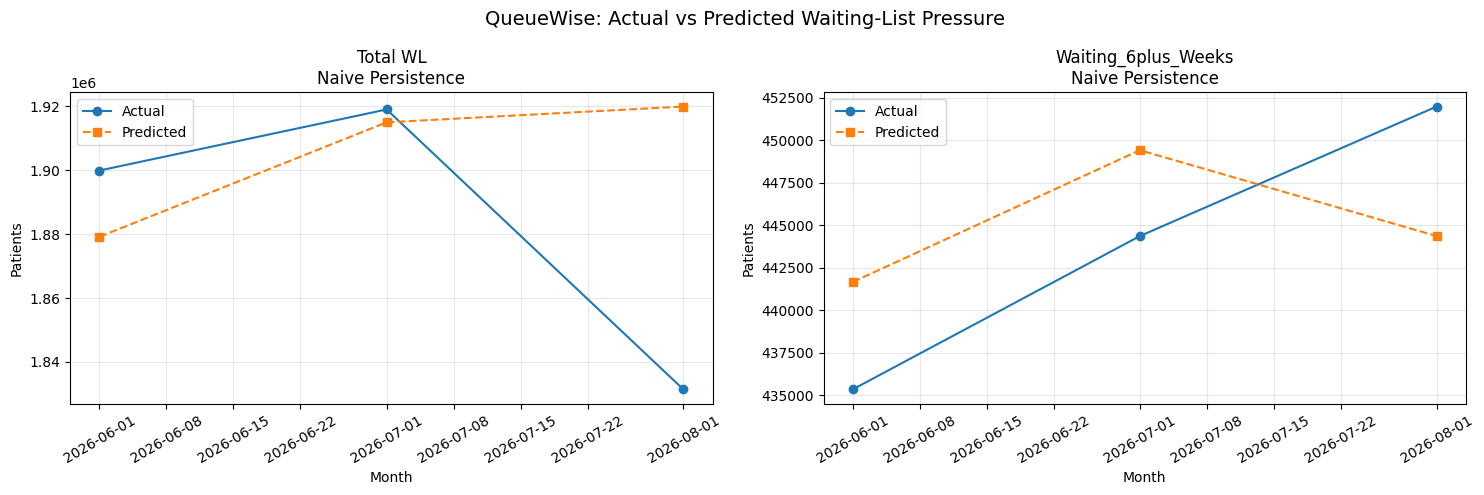

In [16]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, target in zip(
    axes,
    ["Total WL", "Waiting_6plus_Weeks"]
):

    best_name = best_models[target]

    target_label = (
        "Total_WL"
        if target == "Total WL"
        else "Waiting_6plus_Weeks"
    )

    pred_col = (
        f"{target_label}_"
        f"{best_name.replace(' ', '_')}"
    )

    monthly = (
        test_predictions.groupby("month")[
            [target, pred_col]
        ].sum()
        .reset_index()
    )

    ax.plot(
        monthly["month"],
        monthly[target],
        marker="o",
        label="Actual"
    )

    ax.plot(
        monthly["month"],
        monthly[pred_col],
        marker="s",
        linestyle="--",
        label="Predicted"
    )

    ax.set_title(f"{target}\n{best_name}")
    ax.set_xlabel("Month")
    ax.set_ylabel("Patients")
    ax.legend()
    ax.grid(alpha=0.3)

    ax.tick_params(axis="x", rotation=30)

plt.suptitle(
    "QueueWise: Actual vs Predicted Waiting-List Pressure",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/"
    "QueueWise_Actual_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Generate uncertainty estimates

In [17]:

import pandas as pd
import numpy as np

# Categorize waiting-list size for fairer uncertainty estimates
def pressure_band(values):
    values = np.asarray(values, dtype=float)
    return np.select(
        [
            values == 0,
            values < 50,
            values < 500
        ],
        [
            "Zero",
            "1-49",
            "50-499"
        ],
        default="500+"
    )

calibration_parts = []

target_info = [
    ("Total WL", "total_wl", "Total_WL"),
    ("Waiting_6plus_Weeks", "waiting_6plus",
     "Waiting_6plus_Weeks")
]

for target, label, lag_prefix in target_info:

    for horizon in [1, 2, 3]:

        lag_col = f"{lag_prefix}_lag{horizon}"

        temp = val_df[
            ["Diagnostic Tests", target, lag_col]
        ].copy()

        temp["target"] = label
        temp["horizon_months"] = horizon

        temp["size_band"] = pressure_band(
            temp[lag_col]
        )

        # Amount by which the historical prediction
        # underestimated the actual waiting list
        temp["positive_error"] = (
            temp[target] - temp[lag_col]
        ).clip(lower=0)

        calibration_parts.append(
            temp[
                [
                    "Diagnostic Tests",
                    "target",
                    "horizon_months",
                    "size_band",
                    "positive_error"
                ]
            ]
        )

calibration = pd.concat(
    calibration_parts, ignore_index=True
)

# Detailed uncertainty: service, horizon, size band
uncertainty_stats = (
    calibration.groupby(
        [
            "Diagnostic Tests",
            "target",
            "horizon_months",
            "size_band"
        ]
    )
    .agg(
        n=("positive_error", "size"),
        q90_uplift=(
            "positive_error",
            lambda x: x.quantile(0.90)
        )
    )
    .reset_index()
)

# Fallback for categories with few validation records
service_uncertainty = (
    calibration.groupby(
        ["Diagnostic Tests", "target", "horizon_months"]
    )
    .agg(
        service_q90=(
            "positive_error",
            lambda x: x.quantile(0.90)
        )
    )
    .reset_index()
)

print("Calibration records:", len(calibration))
print("Detailed uncertainty groups:", len(uncertainty_stats))

display(uncertainty_stats.head(12))

uncertainty_stats.to_csv(
    "/content/drive/MyDrive/"
    "QueueWise_Uncertainty_Calibration.csv",
    index=False
)

print("Uncertainty calibration saved!")


Calibration records: 121680
Detailed uncertainty groups: 346


,Diagnostic Tests,target,horizon_months,size_band,n,q90_uplift
0,AUDIOLOGY_ASSESSMENTS,total_wl,1,1-49,44,12.8
1,AUDIOLOGY_ASSESSMENTS,total_wl,1,50-499,171,94.0
2,AUDIOLOGY_ASSESSMENTS,total_wl,1,500+,246,186.5
3,AUDIOLOGY_ASSESSMENTS,total_wl,1,Zero,891,0.0
4,AUDIOLOGY_ASSESSMENTS,total_wl,2,1-49,44,36.4
5,AUDIOLOGY_ASSESSMENTS,total_wl,2,50-499,181,198.0
6,AUDIOLOGY_ASSESSMENTS,total_wl,2,500+,236,366.0
7,AUDIOLOGY_ASSESSMENTS,total_wl,2,Zero,891,0.0
8,AUDIOLOGY_ASSESSMENTS,total_wl,3,1-49,45,41.2
9,AUDIOLOGY_ASSESSMENTS,total_wl,3,50-499,187,236.2


Uncertainty calibration saved!


Forecast September–November 2026

In [18]:

# Load the complete 24-month service-level dataset
full_data = pd.read_csv(
    "/content/drive/MyDrive/QueueWise_24Months_ModelReady.csv",
    parse_dates=["month"],
    dtype={"Provider Org Code": "string"},
    low_memory=False
)

origin = pd.Timestamp("2026-08-01")
latest = full_data[full_data["month"] == origin].copy()

keys = ["Provider Org Code", "Diagnostic Tests"]

assert len(latest) > 0
assert not latest.duplicated(keys).any()
assert (latest["Diagnostic Tests"] != "TOTAL").all()

keep_cols = keys + [
    "Provider Org Name",
    "Total WL",
    "Waiting_6plus_Weeks",
    "Total Activity"
]

# Construct the three forecast horizons
forecast_parts = []

for horizon in [1, 2, 3]:
    part = latest[keep_cols].copy()

    part["forecast_origin"] = origin
    part["forecast_month"] = (
        origin + pd.DateOffset(months=horizon)
    )
    part["horizon_months"] = horizon

    forecast_parts.append(part)

forecast_df = pd.concat(
    forecast_parts, ignore_index=True
)

# Add expected and high-pressure predictions
for target, label, _ in target_info:

    expected_col = f"forecast_{label}_expected"
    high_col = f"forecast_{label}_high"
    uplift_col = f"{label}_uplift"

    forecast_df[expected_col] = (
        forecast_df[target].clip(lower=0)
    )

    forecast_df["size_band"] = pressure_band(
        forecast_df[expected_col]
    )

    # Detailed calibration
    detail = uncertainty_stats[
        uncertainty_stats["target"] == label
    ][
        [
            "Diagnostic Tests", "horizon_months",
            "size_band", "q90_uplift", "n"
        ]
    ].rename(columns={
        "q90_uplift": "group_q90",
        "n": "group_n"
    })

    forecast_df = forecast_df.merge(
        detail,
        on=["Diagnostic Tests", "horizon_months", "size_band"],
        how="left",
        validate="many_to_one"
    )

    # Service-level fallback
    fallback = service_uncertainty[
        service_uncertainty["target"] == label
    ][
        [
            "Diagnostic Tests",
            "horizon_months",
            "service_q90"
        ]
    ]

    forecast_df = forecast_df.merge(
        fallback,
        on=["Diagnostic Tests", "horizon_months"],
        how="left",
        validate="many_to_one"
    )

    assert forecast_df["service_q90"].notna().all()

    # At least 30 observations for size-specific calibration
    forecast_df[uplift_col] = np.ceil(
        np.where(
            forecast_df["group_n"].fillna(0) >= 30,
            forecast_df["group_q90"],
            forecast_df["service_q90"]
        )
    ).astype(int)

    forecast_df = forecast_df.drop(columns=[
        "size_band", "group_q90", "group_n",
        "service_q90"
    ])

    # Make uncertainty non-decreasing with horizon
    forecast_df = forecast_df.sort_values(
        keys + ["horizon_months"]
    )

    forecast_df[uplift_col] = (
        forecast_df.groupby(keys)[uplift_col].cummax()
    )

    forecast_df[high_col] = (
        forecast_df[expected_col] +
        forecast_df[uplift_col]
    )

# The number waiting 6+ weeks cannot exceed total waiting
forecast_df["forecast_waiting_6plus_high"] = np.minimum(
    forecast_df["forecast_waiting_6plus_high"],
    forecast_df["forecast_total_wl_high"]
)

# Check results
assert len(forecast_df) == len(latest) * 3
assert not forecast_df.duplicated(
    keys + ["forecast_month"]
).any()

assert (
    forecast_df["forecast_waiting_6plus_high"] <=
    forecast_df["forecast_total_wl_high"]
).all()

assert (
    forecast_df["forecast_waiting_6plus_expected"] <=
    forecast_df["forecast_total_wl_expected"]
).all()

# Save forecast results for Member 3
forecast_df.to_csv(
    "/content/drive/MyDrive/"
    "QueueWise_Forecast_Scenarios.csv",
    index=False
)

print("Latest provider-service records:", len(latest))
print("Forecast records:", len(forecast_df))

print("\nForecast summary:")
summary = forecast_df.groupby(
    "forecast_month"
)[
    [
        "forecast_total_wl_expected",
        "forecast_total_wl_high",
        "forecast_waiting_6plus_expected",
        "forecast_waiting_6plus_high"
    ]
].sum()

display(summary)

print("\nSample provider-level forecasts:")
display(
    forecast_df[
        [
            "forecast_month",
            "Provider Org Code",
            "Diagnostic Tests",
            "forecast_total_wl_expected",
            "forecast_total_wl_high",
            "forecast_waiting_6plus_expected",
            "forecast_waiting_6plus_high"
        ]
    ].head(10)
)

print("\nForecast CSV saved successfully!")


Latest provider-service records: 6870
Forecast records: 20610

Forecast summary:


,forecast_total_wl_expected,forecast_total_wl_high,forecast_waiting_6plus_expected,forecast_waiting_6plus_high
forecast_month,,,,
2026-09-01,1833070,2117666,452306,616656
2026-10-01,1833070,2305778,452306,725639
2026-11-01,1833070,2490398,452306,776849



Sample provider-level forecasts:


,forecast_month,Provider Org Code,Diagnostic Tests,forecast_total_wl_expected,forecast_total_wl_high,forecast_waiting_6plus_expected,forecast_waiting_6plus_high
0,2026-09-01,A0C5S,AUDIOLOGY_ASSESSMENTS,0,0,0,0
1,2026-10-01,A0C5S,AUDIOLOGY_ASSESSMENTS,0,0,0,0
2,2026-11-01,A0C5S,AUDIOLOGY_ASSESSMENTS,0,0,0,0
3,2026-09-01,A0C5S,BARIUM_ENEMA,0,0,0,0
4,2026-10-01,A0C5S,BARIUM_ENEMA,0,0,0,0
5,2026-11-01,A0C5S,BARIUM_ENEMA,0,0,0,0
6,2026-09-01,A0C5S,COLONOSCOPY,0,0,0,0
7,2026-10-01,A0C5S,COLONOSCOPY,0,0,0,0
8,2026-11-01,A0C5S,COLONOSCOPY,0,0,0,0
9,2026-09-01,A0C5S,CT,0,0,0,0



Forecast CSV saved successfully!


Evaluate forecast uncertainty on held-out test data

In [19]:

import numpy as np
import pandas as pd

audit_rows = []

for horizon in [1, 2, 3]:

    audit = test_df.copy().reset_index(drop=True)
    audit["horizon_months"] = horizon

    for target, label, lag_prefix in target_info:

        lag_col = f"{lag_prefix}_lag{horizon}"
        expected_col = f"{label}_expected"
        high_col = f"{label}_high"

        audit[expected_col] = audit[lag_col].clip(lower=0)

        audit["size_band"] = pressure_band(
            audit[expected_col]
        )

        # Use previously calculated validation calibration
        detail = uncertainty_stats.loc[
            uncertainty_stats["target"] == label,
            [
                "Diagnostic Tests",
                "horizon_months",
                "size_band",
                "n",
                "q90_uplift"
            ]
        ]

        fallback = service_uncertainty.loc[
            service_uncertainty["target"] == label,
            [
                "Diagnostic Tests",
                "horizon_months",
                "service_q90"
            ]
        ]

        temp = audit[
            ["Diagnostic Tests", "horizon_months", "size_band"]
        ].merge(
            detail,
            on=[
                "Diagnostic Tests",
                "horizon_months",
                "size_band"
            ],
            how="left",
            validate="many_to_one"
        ).merge(
            fallback,
            on=["Diagnostic Tests", "horizon_months"],
            how="left",
            validate="many_to_one"
        )

        assert temp["service_q90"].notna().all()

        uplift = np.ceil(
            np.where(
                temp["n"].fillna(0) >= 30,
                temp["q90_uplift"],
                temp["service_q90"]
            )
        )

        audit[high_col] = (
            audit[expected_col].to_numpy()
            + uplift
        )

    # Enforce the clinical counting constraint
    audit["waiting_6plus_high"] = np.minimum(
        audit["waiting_6plus_high"],
        audit["total_wl_high"]
    )

    # Evaluate both forecast targets
    for target, label, _ in target_info:

        actual = audit[target].to_numpy()
        expected = audit[f"{label}_expected"].to_numpy()
        high = audit[f"{label}_high"].to_numpy()

        mae, rmse, wape = calculate_metrics(
            actual, expected
        )

        positive_mask = actual > 0

        audit_rows.append({
            "Target": target,
            "Horizon": horizon,
            "MAE": round(mae, 3),
            "RMSE": round(rmse, 3),
            "WAPE (%)": round(wape, 3),
            "High coverage (%)": round(
                100 * np.mean(actual <= high), 2
            ),
            "Coverage when actual > 0 (%)": round(
                100 * np.mean(
                    actual[positive_mask] <= high[positive_mask]
                ), 2
            ) if positive_mask.any() else np.nan,
            "Zero-to-positive cases": int(
                np.sum((expected == 0) & (actual > 0))
            )
        })

uncertainty_test_results = pd.DataFrame(audit_rows)

print("MULTI-HORIZON FORECAST AND UNCERTAINTY EVALUATION")
display(uncertainty_test_results)

uncertainty_test_results.to_csv(
    "/content/drive/MyDrive/"
    "QueueWise_Multihorizon_Evaluation.csv",
    index=False
)

print("Evaluation saved!")


MULTI-HORIZON FORECAST AND UNCERTAINTY EVALUATION


,Target,Horizon,MAE,RMSE,WAPE (%),High coverage (%),Coverage when actual > 0 (%),Zero-to-positive cases
0,Total WL,1,26.549,111.597,9.466,95.90,89.07,155
1,Waiting_6plus_Weeks,1,12.182,62.933,18.428,95.27,83.73,494
2,Total WL,2,39.276,168.304,14.003,96.03,89.42,201
3,Waiting_6plus_Weeks,2,20.229,108.964,30.601,95.52,84.60,544
4,Total WL,3,49.730,213.002,17.730,96.38,90.35,198
5,Waiting_6plus_Weeks,3,27.197,147.102,41.141,95.10,83.15,559


Evaluation saved!


Create final forecast graph

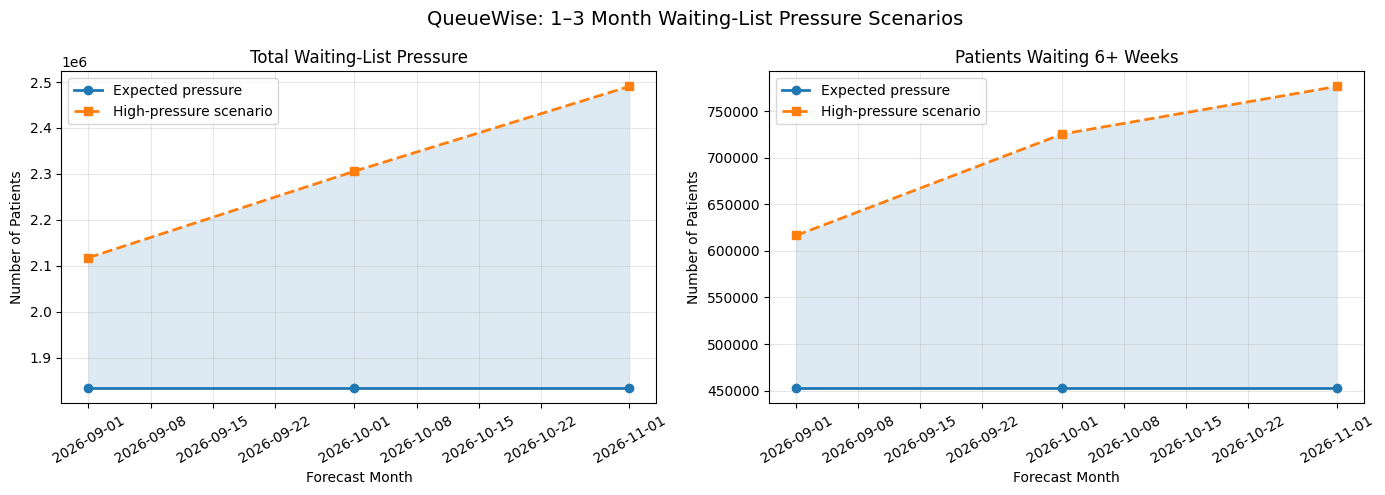

Forecast visualization saved!


In [20]:

import matplotlib.pyplot as plt

forecast_summary = (
    forecast_df.groupby("forecast_month", as_index=False)[
        [
            "forecast_total_wl_expected",
            "forecast_total_wl_high",
            "forecast_waiting_6plus_expected",
            "forecast_waiting_6plus_high"
        ]
    ].sum()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

settings = [
    (
        "Total Waiting-List Pressure",
        "forecast_total_wl_expected",
        "forecast_total_wl_high"
    ),
    (
        "Patients Waiting 6+ Weeks",
        "forecast_waiting_6plus_expected",
        "forecast_waiting_6plus_high"
    )
]

for ax, (title, expected, high) in zip(axes, settings):

    ax.plot(
        forecast_summary["forecast_month"],
        forecast_summary[expected],
        marker="o",
        linewidth=2,
        label="Expected pressure"
    )

    ax.plot(
        forecast_summary["forecast_month"],
        forecast_summary[high],
        marker="s",
        linestyle="--",
        linewidth=2,
        label="High-pressure scenario"
    )

    ax.fill_between(
        forecast_summary["forecast_month"],
        forecast_summary[expected],
        forecast_summary[high],
        alpha=0.15
    )

    ax.set_title(title)
    ax.set_ylabel("Number of Patients")
    ax.set_xlabel("Forecast Month")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "QueueWise: 1–3 Month Waiting-List Pressure Scenarios",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/"
    "QueueWise_Forecast_Scenarios.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Forecast visualization saved!")


Save trained models and final outputs

In [21]:

import joblib
import json
import shutil
from pathlib import Path

# Create final submission directory
output_dir = Path(
    "/content/drive/MyDrive/QueueWise_Member2_Final"
)

model_dir = output_dir / "models"
results_dir = output_dir / "results"
figures_dir = output_dir / "figures"

for folder in [model_dir, results_dir, figures_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# 1. Save fitted preprocessing pipeline
joblib.dump(
    preprocessor,
    model_dir / "preprocessor.joblib"
)

# 2. Save trained ML models
for target in targets:

    target_name = (
        "total_wl"
        if target == "Total WL"
        else "waiting_6plus"
    )

    for model_name in [
        "Linear Regression",
        "XGBoost"
    ]:

        model = trained_models[target][model_name]

        filename = (
            f"{target_name}_"
            f"{model_name.lower().replace(' ', '_')}.joblib"
        )

        joblib.dump(model, model_dir / filename)

# 3. Save selected forecasting method
# Naive Persistence does not require a fitted model file.
configuration = {
    "project": "QueueWise",
    "forecast_origin": "2026-08-01",
    "forecast_horizons": [1, 2, 3],
    "unit_of_analysis": "Provider x Diagnostic Test x Month",
    "selected_models": best_models,
    "selection_metric": "Validation WAPE",
    "expected_scenario": "Naive persistence",
    "high_scenario": "Validation residual-based stress test",
    "high_scenario_is_formal_prediction_interval": False,
    "exclude_total_category": True
}

with open(
    model_dir / "model_configuration.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(configuration, f, indent=4)

# 4. Copy result files
drive_root = Path("/content/drive/MyDrive")

result_files = [
    "QueueWise_Validation_Model_Comparison.csv",
    "QueueWise_Test_Model_Comparison.csv",
    "QueueWise_Test_Predictions.csv",
    "QueueWise_Baseline_Results.csv",
    "QueueWise_Multihorizon_Evaluation.csv",
    "QueueWise_Uncertainty_Calibration.csv",
    "QueueWise_Forecast_Scenarios.csv",
    "QueueWise_24Months_ModelReady.csv",
    "QueueWise_Feature_Engineered.csv"
]

for filename in result_files:

    source = drive_root / filename

    if source.exists():
        shutil.copy2(
            source,
            results_dir / filename
        )
        print("Copied:", filename)
    else:
        print("MISSING:", filename)

# 5. Copy graphs
figure_files = [
    "QueueWise_Actual_vs_Predicted.png",
    "QueueWise_Forecast_Scenarios.png"
]

for filename in figure_files:

    source = drive_root / filename

    if source.exists():
        shutil.copy2(
            source,
            figures_dir / filename
        )
        print("Copied figure:", filename)
    else:
        print("MISSING FIGURE:", filename)

# 6. Display folder contents
print("\nFINAL SUBMISSION CONTENTS")

for file in sorted(output_dir.rglob("*")):
    if file.is_file():
        print(file.relative_to(output_dir))

print("\nExport completed!")


Copied: QueueWise_Validation_Model_Comparison.csv
Copied: QueueWise_Test_Model_Comparison.csv
Copied: QueueWise_Test_Predictions.csv
Copied: QueueWise_Baseline_Results.csv
Copied: QueueWise_Multihorizon_Evaluation.csv
Copied: QueueWise_Uncertainty_Calibration.csv
Copied: QueueWise_Forecast_Scenarios.csv
Copied: QueueWise_24Months_ModelReady.csv
Copied: QueueWise_Feature_Engineered.csv
Copied figure: QueueWise_Actual_vs_Predicted.png
Copied figure: QueueWise_Forecast_Scenarios.png

FINAL SUBMISSION CONTENTS
figures/QueueWise_Actual_vs_Predicted.png
figures/QueueWise_Forecast_Scenarios.png
models/model_configuration.json
models/preprocessor.joblib
models/total_wl_linear_regression.joblib
models/total_wl_xgboost.joblib
models/waiting_6plus_linear_regression.joblib
models/waiting_6plus_xgboost.joblib
results/QueueWise_24Months_ModelReady.csv
results/QueueWise_Baseline_Results.csv
results/QueueWise_Feature_Engineered.csv
results/QueueWise_Forecast_Scenarios.csv
results/QueueWise_Multihorizo

Data Validation: Internal Reconciliation of Provider-Level Waiting-List Totals

In [22]:

import pandas as pd
from pathlib import Path

# Load the complete 24-month dataset
data = pd.read_csv(
    "/content/drive/MyDrive/QueueWise_24Months_Provider.csv",
    parse_dates=["month"],
    dtype={"Provider Org Code": "string"}
)

keys = ["month", "Provider Org Code"]
metrics = ["Total WL", "Waiting_6plus_Weeks"]

# Separate NHS-provided TOTAL rows
total_rows = data[data["Diagnostic Tests"] == "TOTAL"]
service_rows = data[data["Diagnostic Tests"] != "TOTAL"]

# Compare the TOTAL against the sum of 15 services
reported = total_rows.set_index(keys)[metrics]
calculated = service_rows.groupby(keys)[metrics].sum()

comparison = reported.join(
    calculated,
    how="outer",
    lsuffix="_reported",
    rsuffix="_calculated"
)

# Confirm each provider-month is present on both sides
assert comparison.notna().all().all(), (
    "Missing TOTAL or service records detected"
)

for metric in metrics:
    comparison[metric + "_difference"] = (
        comparison[metric + "_reported"]
        - comparison[metric + "_calculated"]
    )

difference_cols = [
    m + "_difference" for m in metrics
]

mismatches = comparison[
    (comparison[difference_cols] != 0).any(axis=1)
]

# National totals by reporting month
monthly_check = (
    comparison.reset_index()
    .groupby("month")
    .agg({
        "Total WL_reported": "sum",
        "Total WL_calculated": "sum",
        "Waiting_6plus_Weeks_reported": "sum",
        "Waiting_6plus_Weeks_calculated": "sum"
    })
)

monthly_check["WL_difference"] = (
    monthly_check["Total WL_reported"]
    - monthly_check["Total WL_calculated"]
)

monthly_check["6plus_difference"] = (
    monthly_check["Waiting_6plus_Weeks_reported"]
    - monthly_check["Waiting_6plus_Weeks_calculated"]
)

print("Months checked:", len(monthly_check))
print("Provider-month records:", len(comparison))
print("Mismatching provider-month records:", len(mismatches))
print("Maximum absolute difference:",
      comparison[difference_cols].abs().max().max())

display(monthly_check)

# Save reconciliation results
output = Path(
    "/content/drive/MyDrive/QueueWise_Member2_Final/results"
)
output.mkdir(parents=True, exist_ok=True)

monthly_check.to_csv(
    output / "QueueWise_24Month_Reconciliation.csv"
)

assert len(monthly_check) == 24
assert len(mismatches) == 0

print("\nPASS: All 24 months are internally consistent!")


Months checked: 24
Provider-month records: 10850
Mismatching provider-month records: 0
Maximum absolute difference: 0


,Total WL_reported,Total WL_calculated,Waiting_6plus_Weeks_reported,Waiting_6plus_Weeks_calculated,WL_difference,6plus_difference
month,,,,,,
2024-09-01,1592553,1592553,361264,361264,0,0
2024-10-01,1636424,1636424,338730,338730,0,0
2024-11-01,1620824,1620824,322929,322929,0,0
2024-12-01,1568661,1568661,357119,357119,0,0
2025-01-01,1627995,1627995,365178,365178,0,0
2025-02-01,1674823,1674823,292432,292432,0,0
2025-03-01,1709380,1709380,313990,313990,0,0
2025-04-01,1703100,1703100,361993,361993,0,0
2025-05-01,1715934,1715934,378352,378352,0,0



PASS: All 24 months are internally consistent!


### Data Reconciliation and Validation

An internal reconciliation check was performed on the complete 24-month NHS DM01 dataset covering September 2024 to August 2026.

For each provider and reporting month, the aggregated waiting-list totals from the 15 individual diagnostic categories were compared against the corresponding `TOTAL` category.

The check covered 10,850 provider-month records across 24 reporting periods. No discrepancies were identified for either total waiting-list size or the number of patients waiting six weeks or longer. The maximum absolute difference was zero.

These findings confirm internal consistency between the diagnostic-service records and the reported total rows. However, independent reconciliation against published NHS national statistics remains a recommended validation step.

### Forecasting and Uncertainty Limitations

The selected Naive Persistence model performed best on validation WAPE for both forecasting targets. However, forecast accuracy decreased with longer prediction horizons, particularly for patients waiting six weeks or longer.

The high-pressure scenarios were constructed using historical underprediction errors and should be interpreted as empirical stress-test scenarios rather than formally calibrated prediction intervals.

Overall high-scenario coverage was approximately 95–96%, but coverage for records with nonzero waiting lists was lower. This limitation should be considered when interpreting the forecasts for healthcare capacity planning.